# Week 4 - Univariate Analysis, part 2

# 1. Lesson - None

# 2. Weekly graph question

Below are a histogram and boxplot representation of the same data. A pharmacy is keeping a record of the prices of the drugs that it sells, and an administrator wants to know how much the more expensive drugs tend to cost, in the context of the other prices.

Please write a short explanation of the pros and cons of these two representations. Which would you choose? How would you modify the formatting, if at all, to make it more visually interesting, clear, or informative?

In [5]:
import numpy as np
import pandas as pd


np.random.seed(0)
num_data = 100
data = np.exp(np.random.uniform(size = num_data) * 4)
df = pd.DataFrame(data.T, columns = ["data"])

The 75th percentile is: data    15.457656
Name: 0.75, dtype: float64


<Axes: ylabel='Frequency'>

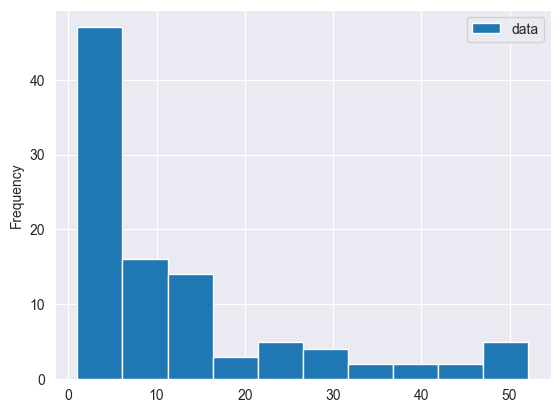

In [6]:
print("The 75th percentile is:", df.quantile(q = 0.75))
df.plot.hist()

<Axes: >

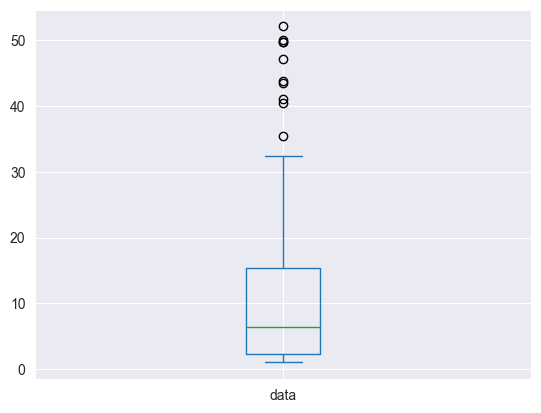

In [7]:
df.plot.box()

In [8]:
# Explanation of the Plots

# The histogram shows the distribution of drug prices and the frequency of drugs within each price range. You can clearly see a right skew of the data with most drugs costing between $0 - $5. As drug prices increase, the number of drugs in each price range decreases. Very few drugs cost between $35 and $40 or higher. The histogram shows the shape of the data, but it does not show median, outliers, and the quartiles.
# The boxplot shows the data using median and quartiles as well as outliers. The boxplot shows that the distribution is positively skewed and that expensive drugs as outliers. The visualization shows where the more expensive drugs fall in comparison to the majority of drug prices. However, the boxplot does not show the overall shape of the distribution like the histogram.
# Overall, I would select the boxplot because it clearly shows the outliers and that the upper 25% of pries begin near th 75th percentile with an approximate value of $15.46. In other words, most drugs about 75%of the drugs cost $15.46 or less, while 25% of the drugs cost more than $15.46. This will help the pharmacy administrator quickly identify higher priced drugs and how they compare to the inventory of drugs. 

# 3. Homework - working on your chosen project datasets this semester

This week, you will do the same types of exercises as last week, but you should use your chosen datasets that someone in your class found last semester. (They likely will not be the particular datasets that you found yourself.)

### Here are some types of analysis you can do:

- Draw histograms and histogram variants for each feature or column.  (Swarm plot, kde plot, violin plot).

- Draw grouped histograms.  For instance, if you have tree heights for both maple and oak trees, you could draw histograms for both.

- Draw a bar plot to indicate total counts of each categorical variable in a given column.

- Find means, medians, and modes.

### Conclusions:

- Explain what conclusions you would draw from this analysis: are the data what you expect?  Are the data likely to be usable?  If they are not useable, find some new data!

- What is the overall shape of the distribution?  Is it normal, skewed, bimodal, uniform, etc.?

- Are there any outliers present?  (Data points that are far from the others.)

- If there are multiple related histograms, how does the distribution change across different groups?

- What are the minimum and maximum values represented in each histogram?

- How do bin sizes affect the histogram?  Does changing the bin width reveal different patterns in the data?

- Does the distribution appear normal, or does it have a different distribution?

Behavioral Risk Factor Surveillance System (BRFSS) Analysis

In [9]:
import  matplotlib.pyplot as plt
import seaborn as sns

In [10]:
#Analysis

df_brfss = pd.read_csv("BRFSS.csv")
df_brfss.shape

(337894, 301)

In [11]:
df_brfss.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 337894 entries, 0 to 337893
Columns: 301 entries, _STATE to _AIDTST4
dtypes: float64(171), int64(130)
memory usage: 776.0 MB


In [12]:
#Duplicated
df_brfss.duplicated().sum()

np.int64(0)

In [13]:
df_brfss.isnull().sum().sort_values(ascending=False).head(20)

_AIDTST4    1
_PNEUMO3    1
_FLSHOT7    1
_RFDRHV9    1
_DRNKWK3    1
_RFBING6    1
DROCDY4_    1
_CRCREC3    1
_SBONTI2    1
_VIRCOL2    1
_STOLDN2    1
_RFBLDS6    1
_SGMS102    1
_SGMSCP2    1
_HADSIGM    1
_CLNSCP2    1
_HADCOLN    1
_PAPHPV1    1
_HPV5YR1    1
_RFPAP37    1
dtype: int64

In [14]:
df_brfss.describe()

,_STATE,FMONTH,IDATE,IMONTH,IDAY,IYEAR,DISPCODE,SEQNO,_PSU,CTELENM1,...,_LCSCTSN,_LCSPSTF,DRNKANY6,DROCDY4_,_RFBING6,_DRNKWK3,_RFDRHV9,_FLSHOT7,_PNEUMO3,_AIDTST4
count,337894.000000,337894.000000,3.378940e+05,337894.000000,337894.000000,337894.000000,337894.000000,3.378940e+05,3.378940e+05,337894.000000,...,337893.000000,337893.000000,337893.000000,337893.000000,337893.000000,337893.000000,337893.000000,337893.000000,337893.000000,337893.000000
mean,23.471630,6.355008,6.763469e+06,6.606181,15.526363,2024.042206,1118.914512,2.024007e+09,2.024007e+09,0.173069,...,2.925565,7.485225,2.206062,102.043644,1.966954,10668.724182,1.887455,0.917927,0.965371,1.801994
std,11.088774,3.348784,3.300360e+06,3.300439,8.649596,0.201058,39.162443,8.014656e+03,8.014656e+03,0.378308,...,1.404410,3.241282,2.249909,263.838303,2.437725,30452.191712,2.436700,2.001340,2.141465,1.684865
min,1.000000,1.000000,1.012025e+06,1.000000,1.000000,2024.000000,1100.000000,2.024000e+09,2.024000e+09,0.000000,...,0.000000,0.000000,1.000000,0.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000
25%,15.000000,3.000000,4.102024e+06,4.000000,8.000000,2024.000000,1100.000000,2.024002e+09,2.024002e+09,0.000000,...,3.000000,9.000000,1.000000,0.000000,1.000000,0.000000,1.000000,0.000000,0.000000,1.000000
50%,24.000000,6.000000,7.022024e+06,7.000000,15.000000,2024.000000,1100.000000,2.024005e+09,2.024005e+09,0.000000,...,3.000000,9.000000,2.000000,3.000000,1.000000,47.000000,1.000000,0.000000,0.000000,2.000000
75%,34.000000,9.000000,9.272024e+06,9.000000,23.000000,2024.000000,1100.000000,2.024008e+09,2.024008e+09,0.000000,...,4.000000,9.000000,2.000000,30.000000,1.000000,467.000000,1.000000,1.000000,1.000000,2.000000
max,41.000000,12.000000,1.231202e+07,12.000000,31.000000,2025.000000,1200.000000,2.024044e+09,2.024044e+09,1.000000,...,4.000000,9.000000,9.000000,900.000000,9.000000,99900.000000,9.000000,9.000000,9.000000,9.000000


In [15]:
#Chronic Disease Variables

chronic_df = df_brfss  [[
    'DIABETE4', #Diabetes
    'CVDINFR4', #Heart Attack
    'CVDCRHD4', #Coronary Heart Disease
    'CVDSTRK3', #Stroke
    'CHCCOPD3', #COPD
    'CHCKDNY2', #Kidney Disease
    'HAVARTH4', #Arthritis
    'PHYSHLTH', #Physical Health
    'MENTHLTH', #Mental Health
    
    #Demographics
    '_STATE',
    '_AGEG5YR',
    '_SEX',
    '_RACEGR3',
    '_EDUCAG',
    '_INCOMG1',
    
    #Health Status
    'GENHLTH' #General Health 
    
]].copy() 

In [16]:
chronic_df.shape   

(337894, 16)

In [17]:
chronic_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 337894 entries, 0 to 337893
Data columns (total 16 columns):
 #   Column    Non-Null Count   Dtype  
---  ------    --------------   -----  
 0   DIABETE4  337894 non-null  int64  
 1   CVDINFR4  337894 non-null  int64  
 2   CVDCRHD4  337894 non-null  int64  
 3   CVDSTRK3  337894 non-null  int64  
 4   CHCCOPD3  337894 non-null  int64  
 5   CHCKDNY2  337894 non-null  int64  
 6   HAVARTH4  337894 non-null  int64  
 7   PHYSHLTH  337894 non-null  int64  
 8   MENTHLTH  337894 non-null  int64  
 9   _STATE    337894 non-null  int64  
 10  _AGEG5YR  337893 non-null  float64
 11  _SEX      337893 non-null  float64
 12  _RACEGR3  337893 non-null  float64
 13  _EDUCAG   337893 non-null  float64
 14  _INCOMG1  337893 non-null  float64
 15  GENHLTH   337894 non-null  int64  
dtypes: float64(5), int64(11)
memory usage: 41.2 MB


In [18]:
chronic_df.describe()

,DIABETE4,CVDINFR4,CVDCRHD4,CVDSTRK3,CHCCOPD3,CHCKDNY2,HAVARTH4,PHYSHLTH,MENTHLTH,_STATE,_AGEG5YR,_SEX,_RACEGR3,_EDUCAG,_INCOMG1,GENHLTH
count,337894.000000,337894.000000,337894.000000,337894.000000,337894.000000,337894.000000,337894.000000,337894.000000,337894.000000,337894.000000,337893.000000,337893.000000,337893.000000,337893.000000,337893.000000,337894.000000
mean,2.741443,1.977079,1.988881,1.971680,1.942683,1.971473,1.684946,58.029998,57.684454,23.471630,7.756393,1.525003,1.813592,3.071961,5.374562,2.661065
std,0.762549,0.493860,0.572259,0.366926,0.459301,0.416901,0.633953,37.845226,38.078234,11.088774,3.746915,0.499375,1.640542,1.045369,2.278581,1.080566
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000
25%,3.000000,2.000000,2.000000,2.000000,2.000000,2.000000,1.000000,12.000000,10.000000,15.000000,5.000000,1.000000,1.000000,2.000000,4.000000,2.000000
50%,3.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,88.000000,88.000000,24.000000,8.000000,2.000000,1.000000,3.000000,5.000000,3.000000
75%,3.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,88.000000,88.000000,34.000000,11.000000,2.000000,2.000000,4.000000,7.000000,3.000000
max,9.000000,9.000000,9.000000,9.000000,9.000000,9.000000,9.000000,99.000000,99.000000,41.000000,14.000000,2.000000,9.000000,9.000000,9.000000,9.000000


In [19]:
chronic_df.median()

DIABETE4     3.0
CVDINFR4     2.0
CVDCRHD4     2.0
CVDSTRK3     2.0
CHCCOPD3     2.0
CHCKDNY2     2.0
HAVARTH4     2.0
PHYSHLTH    88.0
MENTHLTH    88.0
_STATE      24.0
_AGEG5YR     8.0
_SEX         2.0
_RACEGR3     1.0
_EDUCAG      3.0
_INCOMG1     5.0
GENHLTH      3.0
dtype: float64

In [20]:
chronic_df.mode()

,DIABETE4,CVDINFR4,CVDCRHD4,CVDSTRK3,CHCCOPD3,CHCKDNY2,HAVARTH4,PHYSHLTH,MENTHLTH,_STATE,_AGEG5YR,_SEX,_RACEGR3,_EDUCAG,_INCOMG1,GENHLTH
0,3,2,2,2,2,2,2,88,88,36,10.0,2.0,1.0,4.0,5.0,3


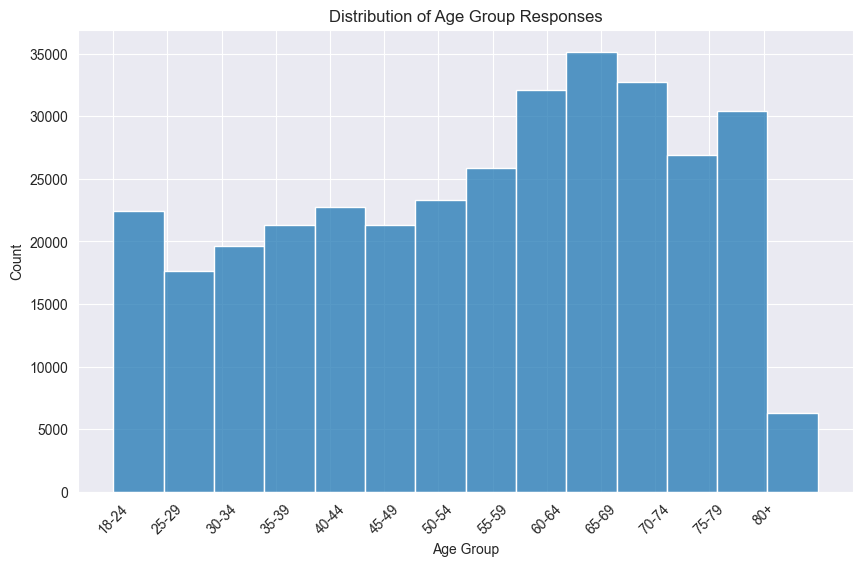

In [21]:
#Histogram

plt.figure(figsize=(10,6))

sns.histplot(
    chronic_df['_AGEG5YR'],
    bins=14,
    kde=False
)

#Age Groups
plt.xticks(
    ticks=range(1,14),
    labels=[
        '18-24','25-29','30-34','35-39', '40-44',
        '45-49','50-54','55-59', '60-64','65-69',
        '70-74','75-79','80+'
    ], rotation=45
)


plt.title('Distribution of Age Group Responses')
plt.xlabel('Age Group')
plt.ylabel('Count')

plt.show()

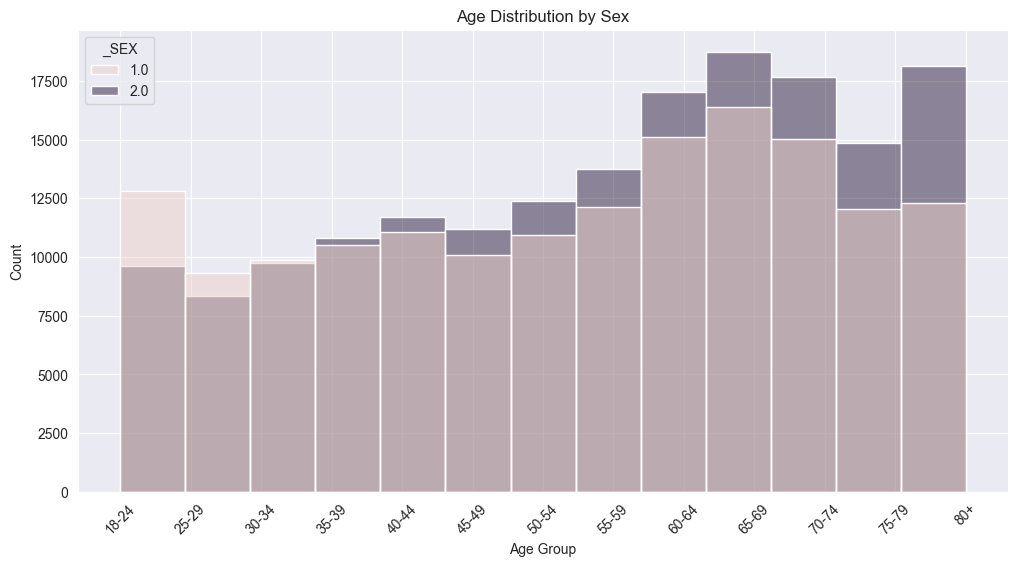

In [22]:
#Grouped Histogram

age_df = chronic_df[chronic_df['_AGEG5YR'] !=14]

plt.figure(figsize=(12,6))

sns.histplot(
    data=age_df,
    x='_AGEG5YR',
    hue='_SEX',
    multiple='layer',
    bins=13
)

plt.title('Age Distribution by Sex')
plt.xlabel('Age Group')
plt.ylabel('Count')


plt.xticks(
    ticks=range(1,14),
    labels=[
        '18-24','25-29','30-34','35-39', '40-44',
        '45-49','50-54','55-59', '60-64','65-69',
        '70-74','75-79','80+'
    ], rotation=45
)


plt.show()

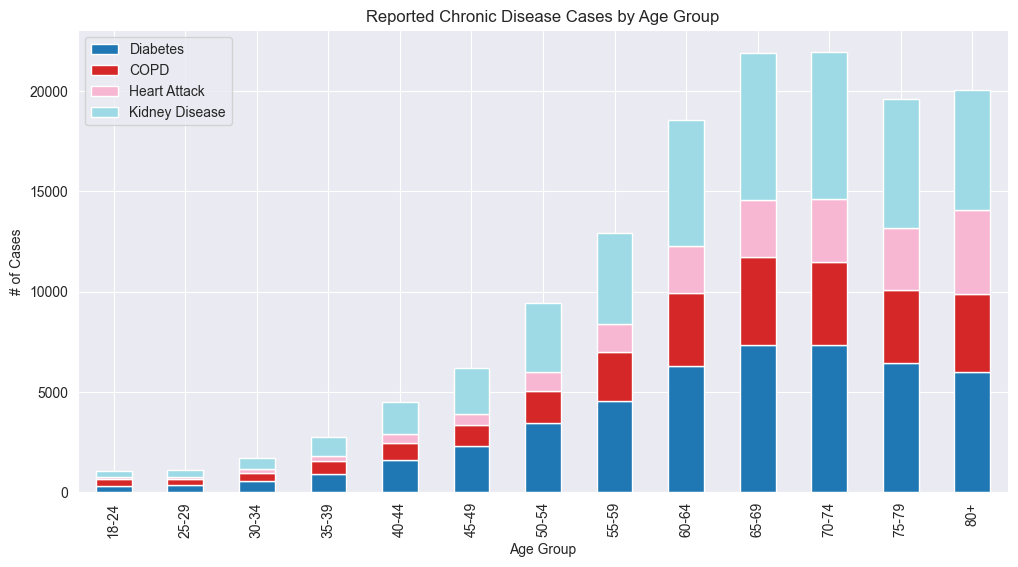

In [23]:
disease_by_age = pd.DataFrame({
    'Diabetes': chronic_df.groupby('_AGEG5YR')['DIABETE4'].apply(lambda x: (x == 1).sum()),
    'COPD': chronic_df.groupby('_AGEG5YR')['CHCCOPD3'].apply(lambda x: (x == 1).sum()),
    'Heart Attack': chronic_df.groupby('_AGEG5YR')['CVDINFR4'].apply(lambda x: (x == 1).sum()),
    'Kidney Disease': chronic_df.groupby('_AGEG5YR')['DIABETE4'].apply(lambda x: (x == 1).sum())  
})

#Remove _AGEG5YR category 14
disease_by_age = disease_by_age.iloc[:13]

disease_by_age.index = [
    '18-24','25-29','30-34','35-39', '40-44',
    '45-49','50-54','55-59', '60-64','65-69',
    '70-74','75-79','80+']

disease_by_age.plot(
    kind='bar',
    stacked=True,
    figsize=(12,6),
    colormap='tab20'
)

plt.title('Reported Chronic Disease Cases by Age Group')
plt.xlabel('Age Group')
plt.ylabel('# of Cases')

plt.show()

In [24]:
#Conclusion of BRFSS Analysis

# The stacked bar chart shows a strong relationship between age and chronic disease prevalence. The numer of chronic disease cases reported increases steadily across age groups with the highest prevalence occurring with individuals between the ages of 65-69 and 70-74. Diabetes contributes to the largest share of chronic diseases across all ages followed by COPD. Kidney disease also shows a substantial increase among older adults and becomes one of the most prevalent conditions in adults 60 years or older. Overall, the findings suggest that age is a significant factor associated with chronic disease prevalence, particularly for diabetes and Kidney disease, which become increasingly common as individuals grow older.

National Health and Nutrition Examination Survey (NHANES) Analysis

In [25]:
#Analysis

df_nhanes = pd.read_excel("DEMO_L.xlsx")
df_nhanes.shape

(11933, 27)

In [26]:
df_nhanes.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11933 entries, 0 to 11932
Data columns (total 27 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   SEQN      11933 non-null  int64  
 1   SDDSRVYR  11933 non-null  int64  
 2   RIDSTATR  11933 non-null  int64  
 3   RIAGENDR  11933 non-null  int64  
 4   RIDAGEYR  11933 non-null  int64  
 5   RIDAGEMN  377 non-null    float64
 6   RIDRETH1  11933 non-null  int64  
 7   RIDRETH3  11933 non-null  int64  
 8   RIDEXMON  8860 non-null   float64
 9   RIDEXAGM  2787 non-null   float64
 10  DMQMILIZ  8301 non-null   float64
 11  DMDBORN4  11914 non-null  float64
 12  DMDYRUSR  1875 non-null   float64
 13  DMDEDUC2  7794 non-null   float64
 14  DMDMARTZ  7792 non-null   float64
 15  RIDEXPRG  1503 non-null   float64
 16  DMDHHSIZ  11933 non-null  int64  
 17  DMDHRGND  4115 non-null   float64
 18  DMDHRAGZ  4124 non-null   float64
 19  DMDHREDZ  3746 non-null   float64
 20  DMDHRMAZ  4020 non-null   fl

In [27]:
df_nhanes.describe()

,SEQN,SDDSRVYR,RIDSTATR,RIAGENDR,RIDAGEYR,RIDAGEMN,RIDRETH1,RIDRETH3,RIDEXMON,RIDEXAGM,...,DMDHRGND,DMDHRAGZ,DMDHREDZ,DMDHRMAZ,DMDHSEDZ,WTINT2YR,WTMEC2YR,SDMVSTRA,SDMVPSU,INDFMPIR
count,11933.000000,11933.0,11933.000000,11933.000000,11933.000000,377.000000,11933.000000,11933.000000,8860.000000,2787.000000,...,4115.000000,4124.000000,3746.000000,4020.000000,2127.000000,11933.000000,11933.000000,11933.000000,11933.000000,9892.000000
mean,136344.000000,12.0,1.742479,1.532808,38.317858,11.628647,3.104584,3.320540,1.520203,121.908504,...,1.564277,2.539525,2.171383,1.381095,2.275035,27404.135674,27404.135674,179.918294,1.491746,2.708174
std,3444.904716,0.0,0.437287,0.498943,25.601990,6.805429,1.076346,1.518379,0.499620,67.158655,...,0.495912,0.641094,0.660132,0.681421,0.694050,19449.155209,27962.962514,4.309624,0.499953,1.670119
min,130378.000000,12.0,1.000000,1.000000,0.000000,0.000000,1.000000,1.000000,1.000000,0.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,4584.463196,0.000000,173.000000,1.000000,0.000000
25%,133361.000000,12.0,1.000000,1.000000,13.000000,6.000000,3.000000,3.000000,1.000000,66.000000,...,1.000000,2.000000,2.000000,1.000000,2.000000,14331.753594,0.000000,176.000000,1.000000,1.180000
50%,136344.000000,12.0,2.000000,2.000000,37.000000,11.000000,3.000000,3.000000,2.000000,122.000000,...,2.000000,2.000000,2.000000,1.000000,2.000000,21670.185970,21717.849160,180.000000,1.000000,2.500000
75%,139327.000000,12.0,2.000000,2.000000,62.000000,17.000000,4.000000,4.000000,2.000000,179.500000,...,2.000000,3.000000,3.000000,2.000000,3.000000,33831.331556,38341.150005,184.000000,2.000000,4.500000
max,142310.000000,12.0,2.000000,2.000000,80.000000,24.000000,5.000000,7.000000,2.000000,239.000000,...,2.000000,4.000000,3.000000,3.000000,3.000000,170968.343177,227108.296958,187.000000,2.000000,5.000000


In [28]:
df_nhanes.isnull().sum().sort_values(ascending=False)

RIDAGEMN    11556
RIDEXPRG    10430
DMDYRUSR    10058
DMDHSEDZ     9806
RIDEXAGM     9146
DMDHREDZ     8187
DMDHRMAZ     7913
DMDHRGND     7818
DMDHRAGZ     7809
DMDMARTZ     4141
DMDEDUC2     4139
DMQMILIZ     3632
RIDEXMON     3073
INDFMPIR     2041
DMDBORN4       19
SDDSRVYR        0
SEQN            0
RIDSTATR        0
RIDRETH1        0
RIDRETH3        0
RIAGENDR        0
RIDAGEYR        0
DMDHHSIZ        0
WTINT2YR        0
WTMEC2YR        0
SDMVSTRA        0
SDMVPSU         0
dtype: int64

In [29]:
df_nhanes.duplicated().sum()

np.int64(0)

In [30]:
df_nhanes.mode().iloc[0]

SEQN        130378.000000
SDDSRVYR        12.000000
RIDSTATR         2.000000
RIAGENDR         2.000000
RIDAGEYR        80.000000
RIDAGEMN         6.000000
RIDRETH1         3.000000
RIDRETH3         3.000000
RIDEXMON         2.000000
RIDEXAGM        50.000000
DMQMILIZ         2.000000
DMDBORN4         1.000000
DMDYRUSR         6.000000
DMDEDUC2         5.000000
DMDMARTZ         1.000000
RIDEXPRG         2.000000
DMDHHSIZ         2.000000
DMDHRGND         2.000000
DMDHRAGZ         2.000000
DMDHREDZ         2.000000
DMDHRMAZ         1.000000
DMDHSEDZ         2.000000
WTINT2YR     47011.303315
WTMEC2YR         0.000000
SDMVSTRA       184.000000
SDMVPSU          1.000000
INDFMPIR         5.000000
Name: 0, dtype: float64

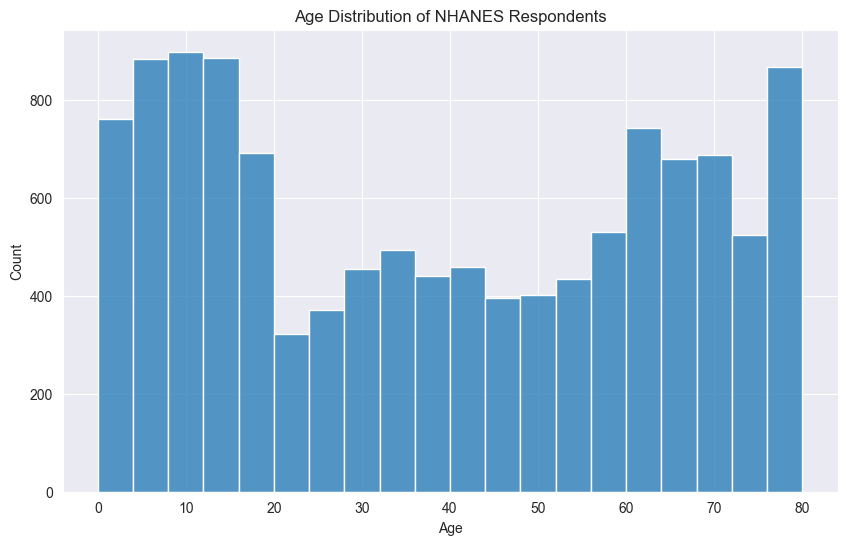

In [31]:
#Histogram Age

plt.figure(figsize=(10,6))

sns.histplot(df_nhanes['RIDAGEYR'], bins=20)

plt.title('Age Distribution of NHANES Respondents')
plt.xlabel('Age')
plt.ylabel('Count')

plt.show()

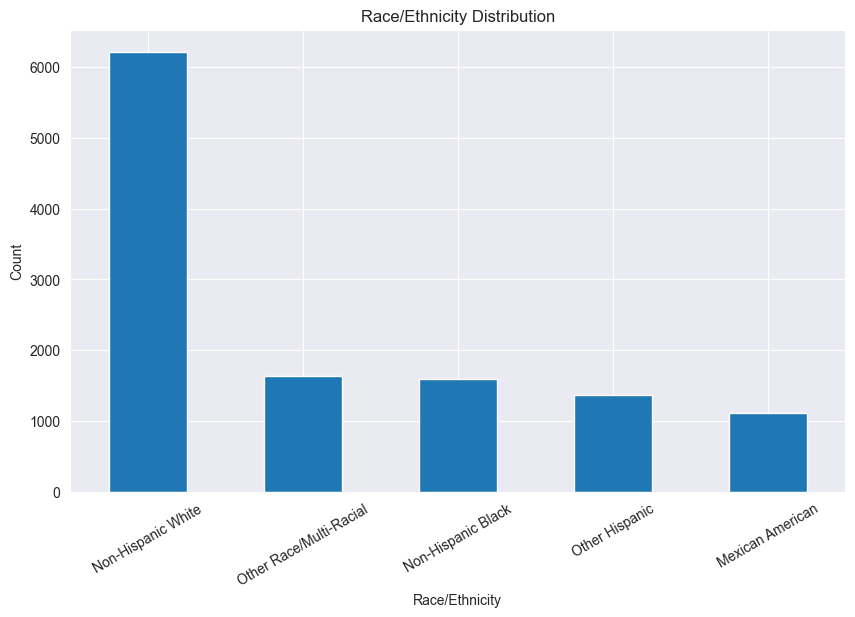

In [32]:
#Race/Ethnicity Distribution

race_mapping = {1:'Mexican American',
                2:'Other Hispanic',
                3:'Non-Hispanic White',
                4:'Non-Hispanic Black',
                5:'Other Race/Multi-Racial'}

race_counts = (df_nhanes['RIDRETH1'].map(race_mapping).value_counts())

plt.figure(figsize=(10,6))

race_counts.plot(kind='bar')

plt.title('Race/Ethnicity Distribution')
plt.xlabel('Race/Ethnicity')
plt.ylabel('Count')

plt.xticks(rotation=30)
plt.show()

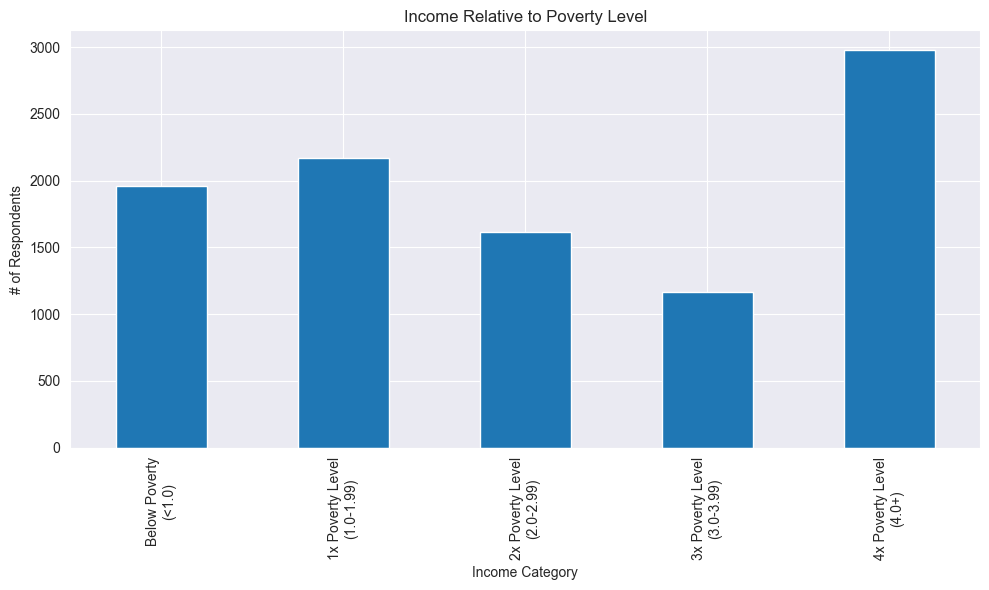

In [33]:
#Income to Poverty Distribution

income_groups = pd.cut(df_nhanes['INDFMPIR'],bins=[0,1,2,3,4,5.01],
                       labels=['Below Poverty\n(<1.0)',
                               '1x Poverty Level\n(1.0-1.99)',
                               '2x Poverty Level\n(2.0-2.99)',
                               '3x Poverty Level\n(3.0-3.99)',
                               '4x Poverty Level\n(4.0+)'
                               ], include_lowest=True)

income_groups.value_counts().sort_index().plot(kind='bar',figsize=(10,6))

plt.title('Income Relative to Poverty Level')
plt.xlabel('Income Category')
plt.ylabel('# of Respondents')


plt.tight_layout()
plt.show()

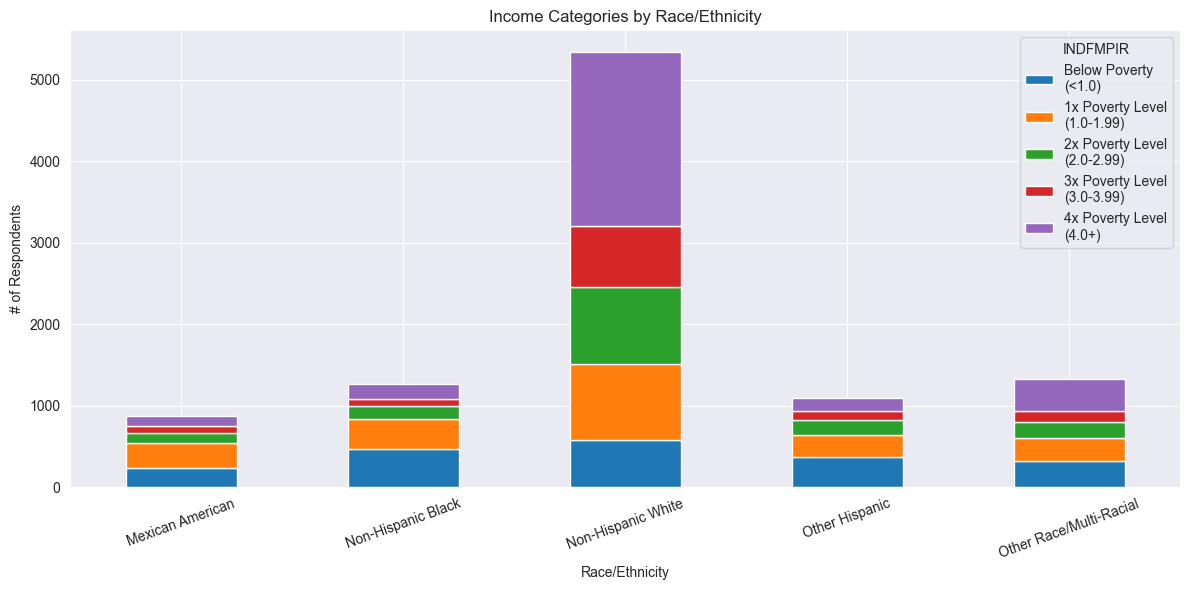

In [34]:
#Grouped Income and Race/Ethnicity

race_mapping = {1:'Mexican American',
                2:'Other Hispanic',
                3:'Non-Hispanic White',
                4:'Non-Hispanic Black',
                5:'Other Race/Multi-Racial'}

income_race = pd.crosstab(df_nhanes['RIDRETH1'].map(race_mapping),income_groups)

income_race.plot(kind='bar',stacked=True,figsize=(12,6))

plt.title('Income Categories by Race/Ethnicity')
plt.xlabel('Race/Ethnicity')
plt.ylabel('# of Respondents')

plt.xticks(rotation=20)

plt.tight_layout()
plt.show()

In [35]:
#Conclusions for NHANES

#Age Distribution: This plot is not normally distributed and shows a higher number of younger respondents and adults between 60 and 80 years old. Respondents ages range between 0 - 80 years old, with a mean age of 38 years old. There are no significant outliers. The histogram was created using 20 bins. 

#Race/Ethnicity Distribution: This plot is very diverse, where Non-Hispanic White represents the largest group of respondents. This distribution is not uniform because the Non-Hispanic White group is more heavily represented than the others. 

#Income Relative to Poverty Level: This plot shows a very strong diversity among income levels for respondents. The income categories range from respondents living below the poverty level (<1.0) to those whose household incomes are four or more times greater than the poverty level (4.0+). Roughly 2000 respondents reported income levels below the poverty line, while the largest group reported incomes 4x greater than the poverty line. The distribution is not normal and is clustered within the highest income category. This dataset is valuable and relevant for analysis of healthcare access and socioeconomic factors that may influence health outcomes.

#Income Categories by Race: The grouped analysis shows differences in income distribution across racial and ethnic groups. Non-Hispanic White respondents represent the largest group and have the highest number of respondents in the 4x Poverty level. In contrast, Mexican American, Other Hispanic, and Non-Hispanic Black respondents show greater representation in the lower income categories, including those who are below the poverty line. The analysis suggests that socioeconomic status varies across racial and ethnic groups and may influence healthcare access and health outcomes

#Overall the NHANES dataset contains 11,933 respondents and 27 demographic and socioeconomic variables. No duplicate records were identified. There were several variables that contained missing values, however that was expected due to their relevance to specific respondent groups. The dataset provides strong demographic and socioeconomic representation across age, race, and income levels. 
 

CMS Program Statistics: Medicare Providers 2023 - Centers for Medicare and Medicaid Services Analysis

In [36]:
#Analysis

df_cms = pd.read_excel("CMS_Providers_Cleaned.xlsx")
df_cms.shape

(96, 7)

In [37]:
df_medical_cms = df_cms[df_cms['All Physician Specialties']=='Medical'].copy()
df_medical_cms.shape

(52, 7)

In [38]:
df_medical_cms.info()

<class 'pandas.core.frame.DataFrame'>
Index: 52 entries, 4 to 55
Data columns (total 7 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Specialty                  52 non-null     object 
 1   2019                       51 non-null     object 
 2   2020                       51 non-null     float64
 3   2021                       51 non-null     float64
 4   2022                       51 non-null     float64
 5   2023                       51 non-null     float64
 6   All Physician Specialties  52 non-null     object 
dtypes: float64(4), object(3)
memory usage: 3.2+ KB


In [39]:
#Fix 2019 column from object to float

df_medical_cms['2019']=pd.to_numeric(df_medical_cms['2019'],errors='coerce')

In [40]:
df_medical_cms.describe()


,2019,2020,2021,2022,2023
count,49.000000,51.000000,51.000000,51.000000,51.000000
mean,8144.918367,7908.529412,7977.117647,8079.686275,8199.764706
std,10524.470293,10505.494649,10556.410277,10699.523841,10888.267500
min,46.000000,40.000000,50.000000,46.000000,44.000000
25%,1599.000000,1215.500000,1324.500000,1332.500000,1316.500000
50%,4021.000000,3791.000000,3865.000000,3955.000000,4033.000000
75%,10077.000000,10018.000000,10040.500000,10132.000000,10266.500000
max,49766.000000,50357.000000,50660.000000,51659.000000,52888.000000


In [41]:
df_medical_cms[['2019','2020','2021','2022','2023']].mode().iloc[0]

2019    46.0
2020    40.0
2021    50.0
2022    46.0
2023    44.0
Name: 0, dtype: float64

In [42]:
df_medical_cms.duplicated().sum()

np.int64(0)

In [43]:
df_medical_cms.isnull().sum()

Specialty                    0
2019                         3
2020                         1
2021                         1
2022                         1
2023                         1
All Physician Specialties    0
dtype: int64

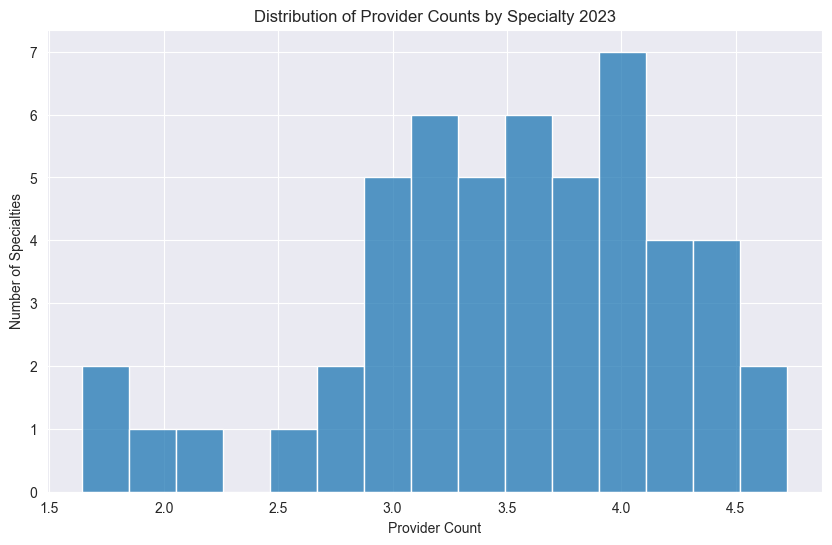

In [44]:
#Histogram

plt.figure(figsize=(10,6))

sns.histplot(np.log10(df_medical_cms['2023']), bins=15)
#Used a logarithmic scale to show the provider counts because there was a substantial range from 44 to 227,687 in 2023 and the chart was not very useful

plt.title('Distribution of Provider Counts by Specialty 2023')
plt.xlabel('Provider Count')
plt.ylabel('Number of Specialties')

plt.show()

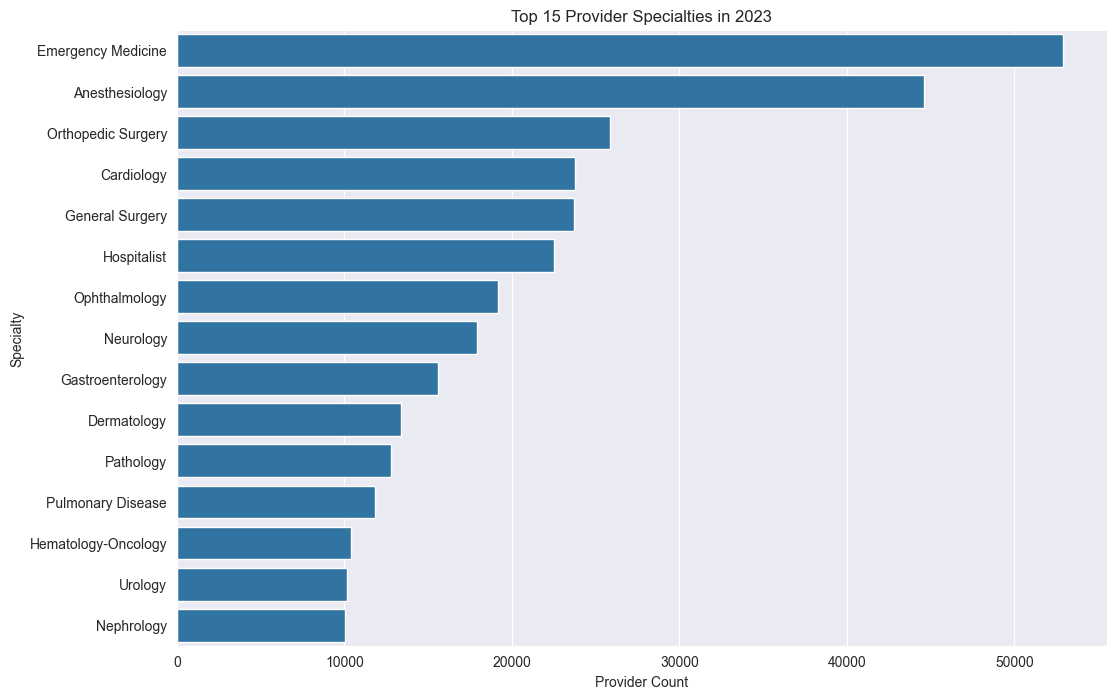

In [45]:
#Top 15 Specialities in 2023

top15 = (df_medical_cms.sort_values('2023',ascending=False).head(15))

plt.figure(figsize=(12,8))

sns.barplot(data=top15,x='2023',y='Specialty')

plt.title('Top 15 Provider Specialties in 2023')
plt.xlabel('Provider Count')
plt.ylabel('Specialty')

plt.show()

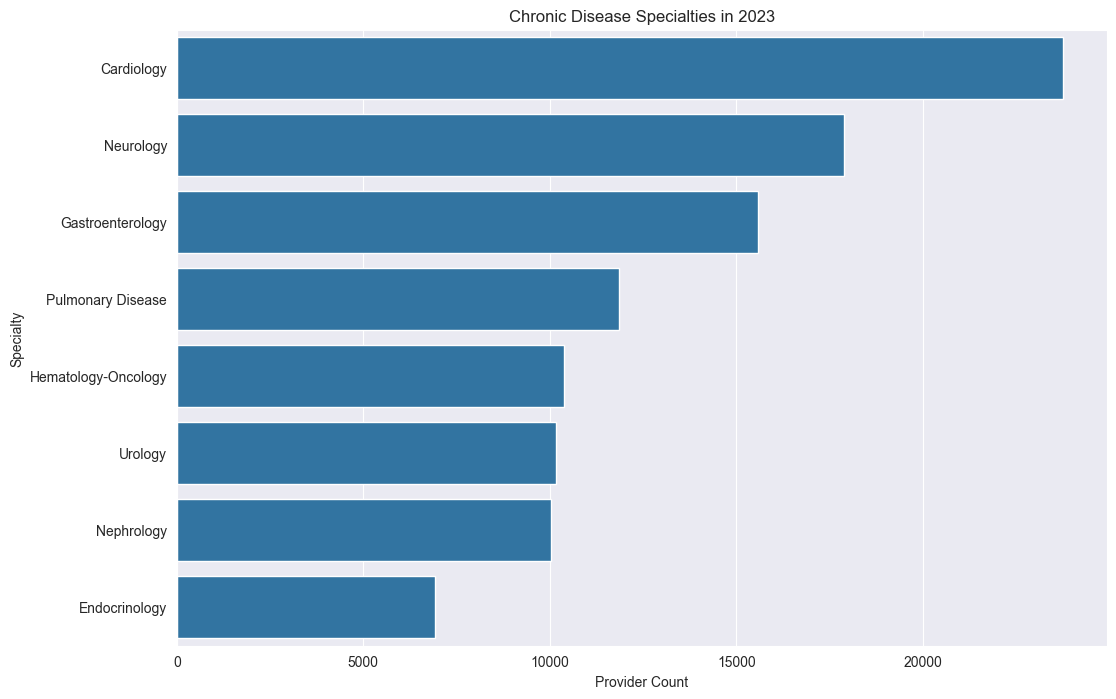

In [46]:
#More Focused Chronic Disease Speciality list

chronic_specialties = ['Cardiology',
                       'Pulmonary Disease',
                       'Neurology',
                       'Nephrology',
                       'Endocrinology',
                       'Gastroenterology',
                       'Hematology-Oncology',
                       'Urology']

chronic_cms = df_medical_cms[df_medical_cms['Specialty'].isin(chronic_specialties)]

chronic_cms_sorted = chronic_cms.sort_values('2023',ascending=False)

plt.figure(figsize=(12,8))

sns.barplot(chronic_cms_sorted,x='2023',y='Specialty')

plt.title('Chronic Disease Specialties in 2023')
plt.xlabel('Provider Count')
plt.ylabel('Specialty')

plt.show()




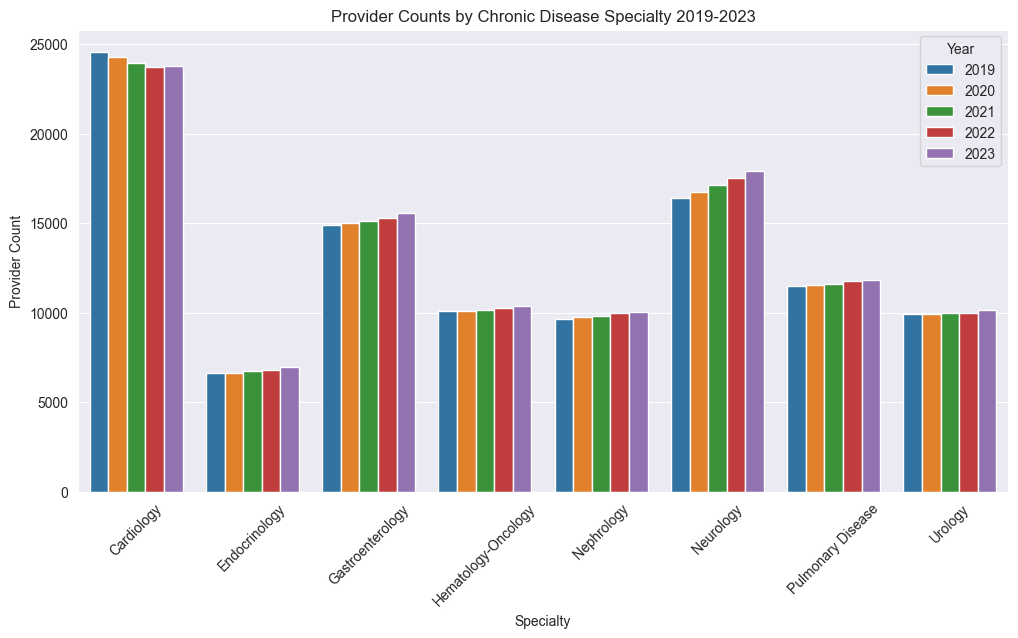

In [47]:
#Provider Counts by Chronic Disease Specialty Across all Years

chronic_long = chronic_cms.melt(
    id_vars='Specialty',
    value_vars=['2019','2020','2021','2022','2023'],
    var_name='Year',
    value_name='Provider_Count')

plt.figure(figsize=(12,6))

sns.barplot(
    data=chronic_long,
    x='Specialty',
    y='Provider_Count',
    hue='Year')

plt.title('Provider Counts by Chronic Disease Specialty 2019-2023')
plt.xlabel('Specialty')
plt.ylabel('Provider Count')

plt.xticks(rotation=45)

plt.show()

In [48]:
#Conclusion

#2023 Distribution by Provider Counts by Specialty: The original distribution was right skewed due to the large differences in provider availability across specialties ranging from 44 to 52,888. A logarithmic transformation was applied to improve the visual and make it more meaningful. After using the logarithmic transformation, the distribution is more balanced and symmetric. The dataset shows a strong variation in provider availability across medical specialties.

#2023 Chronic Disease Specialties: Due to the variation among specialities, the focus was to narrow the specialties to chronic disease or chronic care specialties. Cardiology had the highest provider count, followed by Neurology and Gastroenterology. Pulmonary Disease, Nephrology, and Endocrinology had fewer providers, with Endocrinology representing the smallest provider workforce. This is notable because Diabetes was the most prevalent chronic disease identified in the BRFSS dataset, but Endocrinology had the fewest providers among the chronic disease specialties analyzed.

#2019-2023 Provider Counts by Chronic Disease Specialty: Provider counts remained stable from 2019 through 2023, with small changes across specialties. Neurology and Gastroenterology showed moderate growth, while Cardiology remained the largest specialty with a slight decline over time. Endocrinology remained the smallest provider group. Overall, provider availability across chronic disease specialties changed gradually, suggesting a stable healthcare workforce.

#Overall the CMS dataset contained 52 medical specialties and provider counts from 2019-2023. To better align with the chronic diseases analyzed in the BRFSS dataset, the analysis was narrowed to specialties most directly involved in chronic disease management, including cardiology, Pulmonary disease, Neurology, Nephrology, Endocrinology, Gastroenterology, Hematology-Oncology, and Urology. Data quality was high with no duplicated records and very few missing values. The CMS dataset provides valuable insight into the availability of specialists responsible for treating chronic conditions. When combined with the BRFSS chronic disease findings and NHANES demographic and socioeconomic characteristics, the analysis provides a more complete picture of population health needs and the healthcare workforce available to address those needs.


# 4. Storytelling With Data graph

Reproduce any graph of your choice in p. 52-68 of the Storytelling With Data book as best you can.  (The second half of chapter two).  You do not have to get the exact data values right, just the overall look and feel.

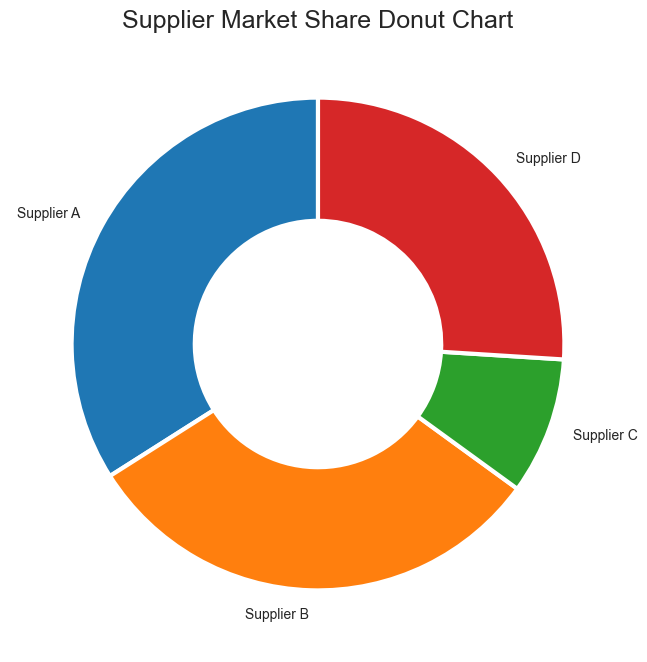

In [49]:
#Donut Chart

#Data
suppliers = ['Supplier A', 'Supplier B', 'Supplier C', 'Supplier D']
market_share = [34,31,9, 26]

#Create Chart
fig, ax = plt.subplots(figsize=(8,8))

ax.pie(market_share,labels=suppliers,startangle=90,wedgeprops=dict(width=0.5,edgecolor='white',linewidth=3))

plt.title('Supplier Market Share Donut Chart', fontsize=18)

plt.show()
